# Training loops

`probjax.nn.training` offers three levels of the same loop:

1. `fit(loss_fn, params, rng, data, **options)` minimises a loss over a plain
   parameter pytree.
2. `fit_module(model, rng, data, loss=...)` trains an `nnx` module in place.
3. `train_step(loss_fn, optimizer)` is one pure `(state, batch) -> (state,
   info)` update for a custom loop.

All three share the same options: `num_steps`, `batch_size`, an optimizer or a
`learning_rate`/`schedule`/`clip_norm`, EMA, callbacks, and a resumable
`state`. This notebook walks through them on the same small regression task.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx

from probjax.nn import MLP
from probjax.nn.training import (
    default_optimizer,
    fit,
    fit_module,
    init_state,
    train_step,
)

## Two small regression tasks

The first target is linear, so a linear model can fit it; the second is a noisy
sine wave for the MLP. Each dataset is one array batch; `fit` minibatches it on
the device.

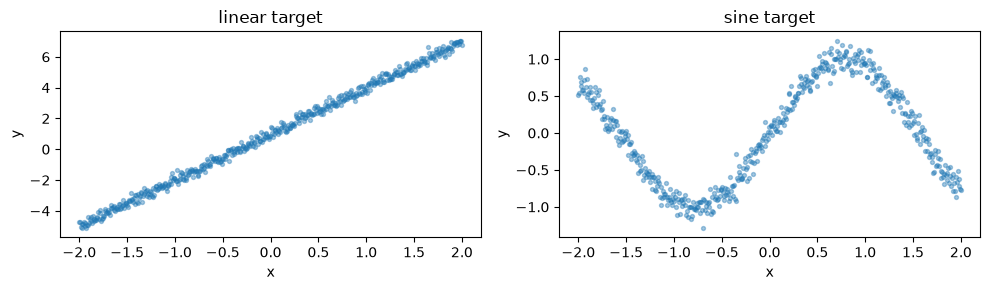

In [2]:
key_w, key_b, key_n = jax.random.split(jax.random.key(0), 3)
x_lin = jnp.linspace(-2.0, 2.0, 512)[:, None]
y_lin = 3.0 * x_lin + 1.0 + 0.2 * jax.random.normal(key_n, x_lin.shape)
linear_data = {"x": x_lin, "y": y_lin}

x_nl = jnp.linspace(-2.0, 2.0, 512)[:, None]
y_nl = jnp.sin(2.0 * x_nl) + 0.1 * jax.random.normal(key_b, x_nl.shape)
sine_data = {"x": x_nl, "y": y_nl}

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].scatter(x_lin[:, 0], y_lin[:, 0], s=8, alpha=0.4)
axes[0].set_title("linear target")
axes[1].scatter(x_nl[:, 0], y_nl[:, 0], s=8, alpha=0.4)
axes[1].set_title("sine target")
for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

## Level 1: fit a parameter pytree

`loss_fn(params, rng, batch)` may return a loss or `(loss, metrics)`; metrics
are stacked into `FitResult.metrics`. A callback runs every `every` updates
and can stop the run by returning `False`.

callback points: [(50, 9.526954650878906), (100, 5.008615493774414), (150, 1.0145769119262695), (200, 0.28031253814697266), (250, 0.1158452108502388), (300, 0.06065325438976288), (350, 0.05158468335866928), (400, 0.0758797898888588)]
final rmse: 0.2754628658294678


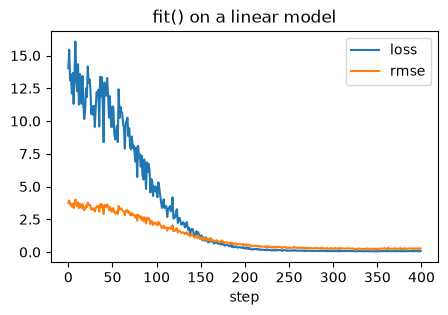

In [3]:
def linear_loss(params, rng, batch):
    prediction = batch["x"] @ params["w"] + params["b"]
    mse = jnp.mean((prediction - batch["y"]) ** 2)
    return mse, {"rmse": jnp.sqrt(mse)}


params = {"w": jnp.zeros((1, 1)), "b": jnp.zeros((1,))}
history = []


def callback(state, info):
    history.append((int(state.step), float(info.loss)))
    return True


result = fit(
    linear_loss,
    params,
    jax.random.key(1),
    linear_data,
    num_steps=400,
    batch_size=64,
    learning_rate=3e-2,
    ema_decay=0.99,
    use_ema=True,
    callback=callback,
    every=50,
)

print("callback points:", history)
print("final rmse:", float(result.metrics["rmse"][-1]))

plt.figure(figsize=(5, 3))
plt.plot(result.losses, label="loss")
plt.plot(result.metrics["rmse"], label="rmse")
plt.xlabel("step")
plt.legend()
plt.title("fit() on a linear model")
plt.show()

`FitResult.params` returns the EMA parameters when `use_ema=True`, while
`FitResult.state.params` keeps the raw optimizer iterate. Passing the final
state back into `fit` resumes exactly where the run stopped.

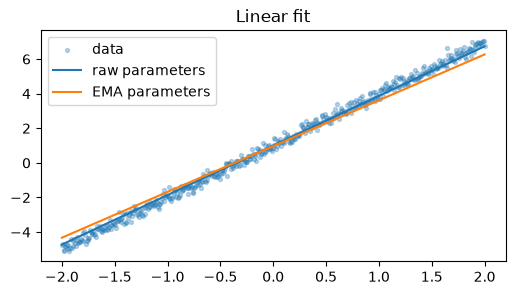

resumed for 50 more steps; final rmse 0.25230035185813904


In [4]:
def predict(params):
    return (x_lin @ params["w"] + params["b"])[:, 0]


plt.figure(figsize=(6, 3))
plt.scatter(x_lin[:, 0], y_lin[:, 0], s=8, alpha=0.3, label="data")
plt.plot(x_lin[:, 0], predict(result.state.params), label="raw parameters")
plt.plot(x_lin[:, 0], predict(result.params), label="EMA parameters")
plt.legend()
plt.title("Linear fit")
plt.show()

more = fit(
    linear_loss,
    params,
    jax.random.key(2),
    linear_data,
    num_steps=50,
    state=result.state,
    ema_decay=0.99,
    use_ema=True,
)
print("resumed for", len(more.losses), "more steps; final rmse", float(more.metrics["rmse"][-1]))

## Level 2: train an nnx module in place

`fit_module` splits the module into trainable parameters and carried state,
runs the same loop, and writes the result back into the module. The loss is
`loss(model, rng, batch)`; the default is `model.loss(rng, batch)`.

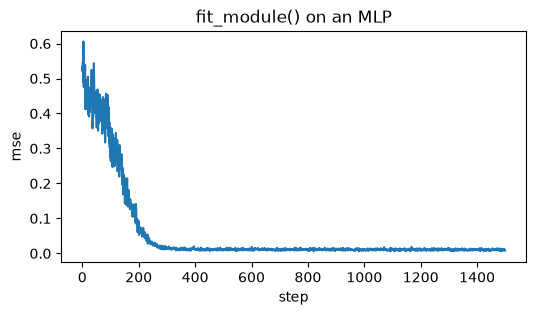

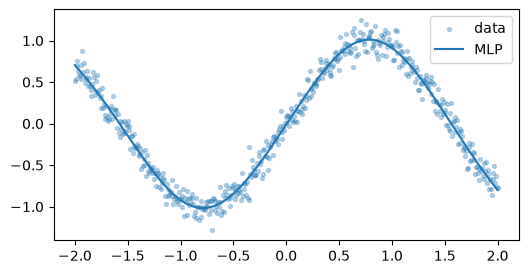

In [5]:
model = MLP([1, 32, 32, 1], rngs=nnx.Rngs(0))


def mlp_loss(model, rng, batch):
    return jnp.mean((model(batch["x"]) - batch["y"]) ** 2)


module_result = fit_module(
    model,
    jax.random.key(3),
    sine_data,
    loss=mlp_loss,
    num_steps=1500,
    batch_size=64,
    learning_rate=3e-3,
)

plt.figure(figsize=(6, 3))
plt.plot(module_result.losses)
plt.xlabel("step")
plt.ylabel("mse")
plt.title("fit_module() on an MLP")
plt.show()

plt.figure(figsize=(6, 3))
plt.scatter(x_nl[:, 0], y_nl[:, 0], s=8, alpha=0.3, label="data")
plt.plot(x_nl[:, 0], model(x_nl)[:, 0], label="MLP")
plt.legend()
plt.show()

## Level 3: a custom loop with train_step

`init_state` and `train_step` expose the same update as a pure function. Jit
it, donate buffers, add logging, or shard it yourself; the step does not own a
loop.

final train_step loss: 0.06366179883480072
steps executed: 400


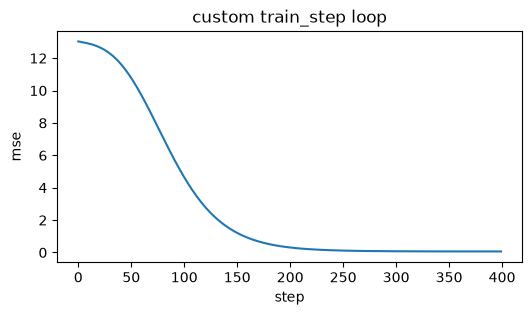

In [6]:
optimizer = default_optimizer(learning_rate=3e-2, num_steps=400)
state = init_state(params, optimizer, jax.random.key(4))
step = jax.jit(train_step(linear_loss, optimizer))

losses = []
for _ in range(400):
    state, info = step(state, linear_data)
    losses.append(info.loss)

print("final train_step loss:", float(losses[-1]))
print("steps executed:", int(state.step))

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("step")
plt.ylabel("mse")
plt.title("custom train_step loop")
plt.show()

## Streams

`fit` treats a mapping, array, or tuple as one in-memory batch and minibatches
it. Any other iterable is a stream: one batch per update, pulled by the Python
loop and never restarted. A stream must supply at least `num_steps` batches.

In [7]:
def batches(num_batches=200, batch_size=32):
    for i in range(num_batches):
        start = (i * batch_size) % (x_lin.shape[0] - batch_size)
        sl = slice(start, start + batch_size)
        yield {"x": x_lin[sl], "y": y_lin[sl]}


stream_result = fit(
    linear_loss,
    params,
    jax.random.key(5),
    batches(),
    num_steps=200,
    learning_rate=3e-2,
)
print("stream final loss:", float(stream_result.losses[-1]))

stream final loss: 0.20714648067951202


## Takeaways

- Use `fit` for a parameter pytree, `fit_module` for an `nnx` module, and
  `train_step` when you need to own the loop.
- Metrics, EMA, callbacks, resume state, and streamed data are options of the
  same loop, so moving between the three levels does not change semantics.
- A callback runs on the host, so it is not available inside a `jit`-traced
  `fit`; use `train_step` there instead.